In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

In [3]:
from schedule import Schedule, Slot
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase
from evaluator import TSNConstraintEvaluator
from tsn_scheduling_problem import TSNScheduling
from env import TSNCandidateHopEnv
from benchmark_utils import build_network_generator_from_usecase, generate_one_arrival_stream, build_usecase_stream_from_request

In [4]:
problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("medium_scenario_2.json")

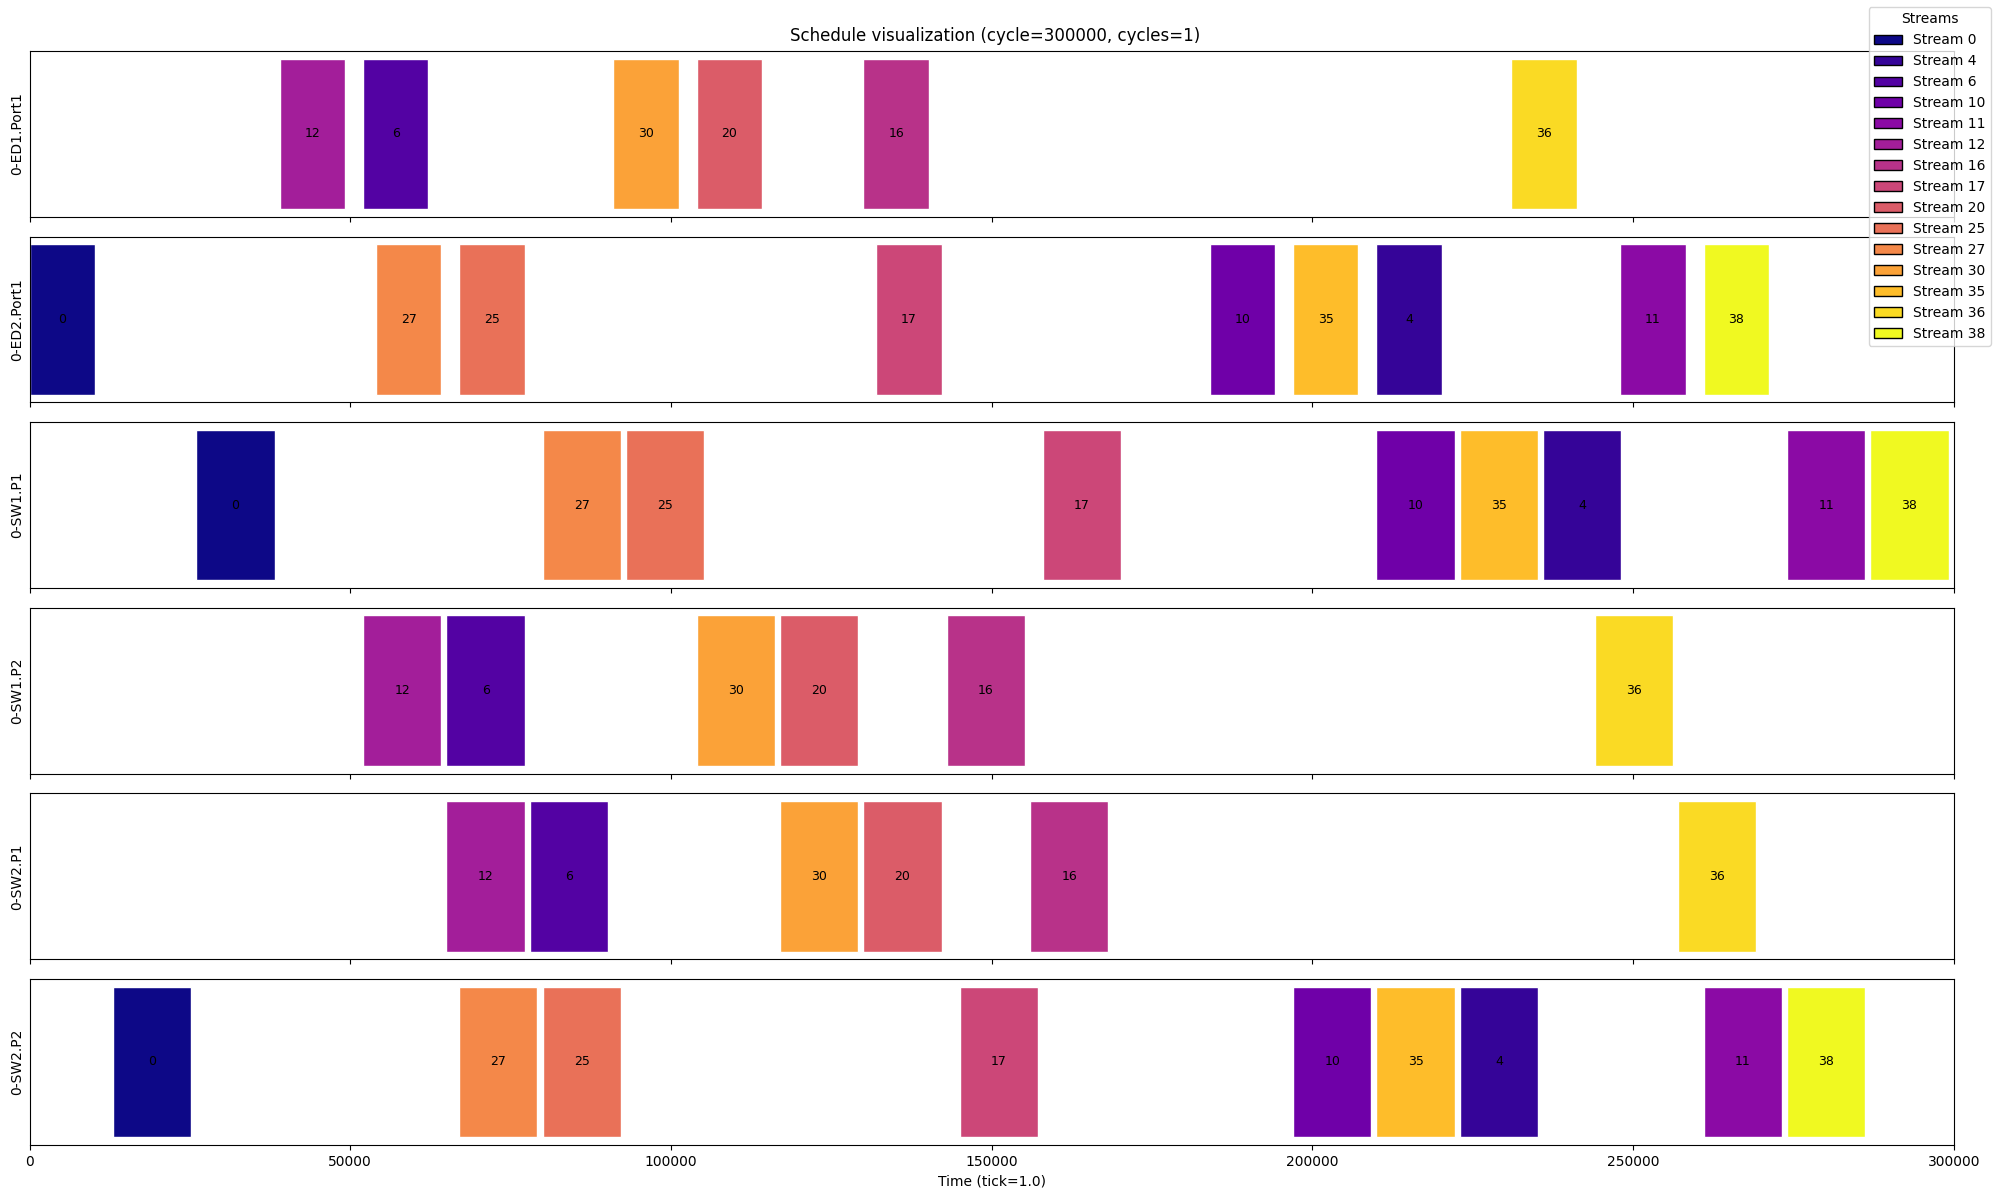

(<Figure size 2000x1200 with 6 Axes>,
 array([<Axes: ylabel='0-ED1.Port1'>, <Axes: ylabel='0-ED2.Port1'>,
        <Axes: ylabel='0-SW1.P1'>, <Axes: ylabel='0-SW1.P2'>,
        <Axes: ylabel='0-SW2.P1'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='0-SW2.P2'>], dtype=object))

In [24]:
instance.schedule.plot(cycles=1, label=True)

In [81]:
def generate_long_arrival_departure_trace(
    instance,
    max_steps=10000,
    lambda_arrival=1.0,
    seed=42,
    ed_ed_settings=None,
):
    import copy
    import numpy as np

    rng_np = np.random.default_rng(seed)
    ng = build_network_generator_from_usecase(copy.deepcopy(instance))

    trace = []

    for _ in range(max_steps):
        n_arr = int(rng_np.poisson(lambda_arrival))

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)

        trace.append({
            "n_dep": 1,          # one departure opportunity per step
            "arrivals": arrivals,
        })

    return trace

In [82]:
import sched
import random
import copy

def run_no_defrag_on_trace(
    instance,
    problem,
    trace,
    seed=42,
    decision_points_per_episode=None,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0
    total_dep = 0
    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    active_stream_ids = sorted({
        slot.stream_id for slot in sched
        if slot.stream_id is not None
    })

    stream_arrival_times = {
        int(sid): 0.0
        for sid in sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
    }

    the_dict = {}

    for step in trace:
        step_count += 1

        # Departures
        active_stream_ids = sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(step["n_dep"], n_active)

        if n_dep > 0:
            res_del = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in res_del["removed_stream_ids"]:
                stream_arrival_times.pop(int(sid), None)

            total_dep += n_dep

        # Arrivals
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                the_dict[total_arrivals] = "reject1"
                raw_none_rejected += 1
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                the_dict[total_arrivals] = "reject2"
                build_none_rejected += 1
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            

            if result["accepted"]:
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                the_dict[total_arrivals] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                the_dict[total_arrivals] = "reject"

            if decision_points_per_episode is not None and total_dep >= decision_points_per_episode:
                break


    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    print(f"Total departures: {total_dep}", f"Total arrivals: {total_arrivals}")

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
        "dict": the_dict,
        "raw_none_rejected": raw_none_rejected,
        "build_none_rejected": build_none_rejected,
        "scheduler_rejected": scheduler_rejected,
    }

In [63]:
def run_of_ff_on_trace(
    instance,
    problem,
    trace,
    p=15,
    n=3,
    seed=42,
):
    import copy
    import random

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0
    departure_counter = 0
    actual_defrag_cycles = 0
    actual_reallocations = 0
    next_defrag_trigger = p

    # Real arrival-time tracker for active streams
    stream_arrival_times = {}

    # Seed currently active initial streams as time 0.0
    initial_active_stream_ids = sorted({
        int(slot.stream_id) for slot in sched
        if slot.stream_id is not None
    })
    for sid in initial_active_stream_ids:
        stream_arrival_times[int(sid)] = 0.0

    the_dict = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departures
        # -------------------------
        active_stream_ids = sorted({
            int(slot.stream_id) for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(int(step["n_dep"]), n_active)

        if n_dep > 0:
            dep_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            removed_ids = dep_result.get("removed_stream_ids", [])
            for sid in removed_ids:
                stream_arrival_times.pop(int(sid), None)

            old_counter = departure_counter
            departure_counter += int(n_dep)

            while departure_counter >= next_defrag_trigger:
                # Trigger OF-FF after departures
                res_defrag=sched.oldest_first_first_fit_defrag(
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )
                if res_defrag.get("triggered", False):
                    actual_defrag_cycles += 1
                    actual_reallocations += int(res_defrag.get("replaced_count", 0))
                next_defrag_trigger += p

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                the_dict[total_arrivals] = "reject1"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                the_dict[total_arrivals] = "reject2"
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )


            if result["accepted"]:
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                the_dict[total_arrivals] = "accept"
            else:
                rejected += 1
                the_dict[total_arrivals] = "reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    if n==0:
         defrag_cycles = 0
         reallocations = 0
    else:
        defrag_cycles = departure_counter // p
        reallocations = defrag_cycles * n

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
        "departures": departure_counter,
        "defrag_cycles": actual_defrag_cycles,
        "reallocations": actual_reallocations,
        "dict": the_dict,
    }

In [64]:
import copy
import random
import numpy as np
import torch

from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def run_drl_on_trace(
    model_path,
    instance,
    problem,
    trace,
    seed=42,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
    debug_drl=False,
    debug_max_actions=50,
):
    """
    Replay one shared arrival/departure trace using the DRL policy.

    IMPORTANT:
    - Benchmark horizon is controlled by the trace (typically 100 arrivals),
      NOT by env decision_points_per_episode.
    - We use the env only for:
        * candidate generation
        * observations
        * applying reallocation actions
    - We do NOT use the env's internal arrival/departure simulator.

    Trace format:
        [
          {"n_dep": int, "arrivals": [raw_stream_or_None, ...]},
          ...
        ]
    """
    rng_py = random.Random(seed)
    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()
    sched = inst.schedule

    # Build a fresh env, but we will bypass its internal simulator loop.
    env = TSNCandidatePathEnv(
        problem=prob,
        usecase=inst,
        useless_gap_threshold_bytes=useless_gap_threshold_bytes,
        expected_incoming_bytes=expected_incoming_bytes,
        invalid_penalty=invalid_penalty,
        max_candidates=max_candidates,
        max_steps=max_steps,
        max_hops=max_hops,
        init_from_usecase_schedule=init_from_usecase_schedule,
        include_current_offset_candidate=include_current_offset_candidate,
        per_hop_candidate_limit=per_hop_candidate_limit,
        beam_width=beam_width,
        defrag_cycle_penalty=defrag_cycle_penalty,
        reallocation_penalty=reallocation_penalty,
        ed_ed_settings=None,
        top_k_oldest_random=top_k_oldest_random,
        seed=seed,
    )

    model = DQN.load(model_path, env=env)

    # Do NOT call reset(), but manually load the initial schedule.
  
    #obs, info = env.reset(seed=seed)
    env._rebuild_runtime_metadata()

    loaded = False
    if init_from_usecase_schedule:
        loaded = env._create_initial_schedule_from_usecase()

    if not loaded:
        env._create_fallback_initial_schedule()

    env._sync_usecase_schedule()
    env._sync_evaluator_with_schedule_durations()
    env._backup_current_as_last_valid()


    # After reset(), the training env may already have advanced internally.
    # For benchmarking on a shared trace, overwrite runtime counters and state semantics.
    env.blocked_requests = 0
    env.total_requests = 0
    env.accepted_requests = 0
    env.current_time = 0.0

    env.episode_invalid_moves = 0
    env.episode_violation_sum = 0
    env.episode_decision_points = 0
    env.episode_reallocations = 0
    env.episode_defrag_cycles = 0

    env.decision_active = False
    env.in_defrag_cycle = False
    env.decision_stream_order = []
    env.decision_pointer = 0
    env.current_candidates = []

    debug_action_counter = 0

    # Initial streams are present from the starting schedule.
    # Keep their "arrival times" at 0.0 for age ordering.
    env.stream_arrival_times = {int(sid): 0.0 for sid in env._active_stream_ids()}

    step_count = 0

    for step in trace:
        step_count += 1
        env.current_time += 1.0

        # --------------------------------------------------
        # 1) Departures from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        active_stream_ids = sorted({
            int(slot.stream_id) for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(int(step["n_dep"]), n_active)

        if n_dep > 0:
            before_ids = list(active_stream_ids)

            sched.delete_streams(
                n_remove=n_dep,
                usecase=env.usecase,
                rng=rng_py,
                port_intervals=env.port_intervals,
                stream_arrival_times=env.stream_arrival_times,
            )

            env._load_state_from_schedule(sched)

            after_ids = env._active_stream_ids()
            removed_ids = env._removed_stream_ids(before_ids, after_ids)
            for sid in removed_ids:
                env.stream_arrival_times.pop(int(sid), None)

            # One decision point occurs because this trace step had departures.
            env.episode_decision_points += 1

            # --------------------------------------------------
            # 2) Let DRL act until STOP or focus list exhausted
            # --------------------------------------------------
            has_decision = env._begin_decision_point()

            if has_decision:
                # We do NOT call env.step(0) because STOP there would trigger
                # the training env's internal simulator advance. Instead, we
                # manually emulate "decision logic only".
                while env.decision_active:
                    obs = env._get_obs()

                    action, _ = model.predict(obs, deterministic=deterministic)
                    action = int(np.asarray(action).item())

                    # -------------------------------
                    # DRL DEBUG: action + Q-values
                    # -------------------------------
                    if debug_drl and debug_action_counter < debug_max_actions:
                        with torch.no_grad():
                            obs_tensor, _ = model.policy.obs_to_tensor(obs)
                            q_values = model.q_net(obs_tensor)
                            q_values = q_values.cpu().numpy()[0]

                        mask = obs["candidate_mask"]
                        mask = np.asarray(mask).reshape(-1)

                        available_actions = np.where(mask > 0)[0]
                        n_candidates_available = max(0, len(available_actions) - 1)

                        print("\n[DRL DEBUG]")
                        print(f"Trace step              : {step_count}")
                        print(f"Current time            : {env.current_time}")
                        print(f"Decision pointer        : {env.decision_pointer}/{len(env.decision_stream_order)}")
                        print(f"Focus stream            : {getattr(env.focus, 'stream_id', None)}")
                        print(f"Available actions       : {available_actions.tolist()}")
                        print(f"Candidates available    : {n_candidates_available}")
                        print(f"Chosen action           : {action}")
                        print(f"STOP Q-value            : {q_values[0]:.6f}")

                        for a in available_actions:
                            label = "STOP" if a == 0 else f"CAND {a-1}"
                            print(f"Action {a:2d} ({label:7s}) | Q={q_values[a]: .6f}")

                        debug_action_counter += 1

                    # Padding -> STOP
                    if action > 0:
                        cand_idx = action - 1
                        if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                            action = 0

                    # STOP: end only the current decision point (no internal sim advance)
                    if action == 0:
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : STOP")
                            print("Reward after action     : 0.000000  # manual benchmark STOP")
                            print(f"Reallocations so far    : {env.episode_reallocations}")
                            print(f"Defrag cycles so far    : {env.episode_defrag_cycles}")

                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    # Candidate application branch (mirrors env.step logic,
                    # but without calling _finish_decision_point_and_continue()).
                    cand_idx = action - 1
                    chosen_candidate = env.current_candidates[cand_idx]

                    saved_ports = copy.deepcopy(env.port_schedules)
                    saved_offsets = copy.deepcopy(env.stream_offsets)

                    applied = env._apply_stream_move(
                        chosen_candidate.stream_id,
                        chosen_candidate.offsets,
                    )

                    if not applied:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : INVALID / NOT APPLIED")
                            print(f"Reward after action     : {-float(invalid_penalty):.6f}")
                        break

                    violation_sum = env._violation_sum()
                    env.episode_violation_sum += int(violation_sum)

                    if violation_sum != 0:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        if debug_drl and debug_action_counter <= debug_max_actions:
                            print("Applied action          : INVALID / VIOLATION")
                            print(f"Violation sum           : {violation_sum}")
                            print(f"Reward after action     : {-float(invalid_penalty):.6f}")
                        break

                    # Valid reallocation
                    env._backup_current_as_last_valid()
                    env.episode_reallocations += 1
                    debug_reward = -float(reallocation_penalty)

                    if not env.in_defrag_cycle:
                        env.in_defrag_cycle = True
                        env.episode_defrag_cycles += 1
                        debug_reward -= float(defrag_cycle_penalty)

                    # Move to next focus stream within this decision point
                    env._advance_stream_focus()

                    if env.decision_pointer >= len(env.decision_stream_order):
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    env.current_candidates = env._candidate_list_for_stream(
                        int(env.focus.stream_id)
                    )

                    if debug_drl and debug_action_counter <= debug_max_actions:
                        print("Applied action          : REALLOCATION")
                        print(f"Moved stream            : {chosen_candidate.stream_id}")
                        print(f"New offsets             : {chosen_candidate.offsets}")
                        print(f"Violation sum           : {violation_sum}")
                        print(f"Reward after action     : {debug_reward:.6f}  # penalty-only proxy")
                        print(f"Reallocations so far    : {env.episode_reallocations}")
                        print(f"Defrag cycles so far    : {env.episode_defrag_cycles}")

        # --------------------------------------------------
        # 3) Arrivals from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        for raw_stream in step["arrivals"]:
            env.total_requests += 1

            if raw_stream is None:
                env.blocked_requests += 1
                continue

            stream_id = len(env.usecase.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                env.usecase,
                k_paths=1,
            )
            if stream is None:
                env.blocked_requests += 1
                continue

            result = sched.place_stream_first_fit_fast(
                stream=stream,
                usecase=env.usecase,
                problem=env.problem,
                port_intervals=env.port_intervals,
                max_candidates_per_hop=2,
                beam_width=3,
            )

            env._rebuild_runtime_metadata()

            accepted_ids = result.get("accepted", [])

            if accepted_ids:
                env.accepted_requests += 1
                new_sid = int(accepted_ids[-1])
                env.stream_arrival_times[new_sid] = float(env.current_time)
            else:
                env.blocked_requests += 1

            env._load_state_from_schedule(sched)

    total_arrivals = int(env.total_requests)
    rejections = int(env.blocked_requests)
    accepted = int(env.accepted_requests)

    sbr = rejections / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    result = {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "steps": int(step_count),
        "accepted": accepted,
        "rejected": rejections,
        "arrivals": total_arrivals,
        "decision_points": int(env.episode_decision_points),
        "invalid_moves": int(env.episode_invalid_moves),
        "reallocations": int(env.episode_reallocations),
        "defrag_cycles": int(env.episode_defrag_cycles),
    }

    env.close()
    return result

In [83]:
import copy
def benchmark_shared_trace(
    methods,
    instance,
    problem,
    n_episodes=10,
    arrivals_per_episode=None,
    decision_points_per_episode=200,
    lambda_arrival=0.1,
    mu_departure=0.05,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
    model_path=None,
    p=15,
    n=3,
    p2=10,
    n2=5,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
    debug_drl=True,
    debug_max_actions=30,
):
    """
    Flexible shared-trace benchmark.

    methods: tuple/list containing any of:
        - "no_defrag"
        - "of_ff"
        - "of_ff2"
        - "drl"

    Returns dict with arrays for requested methods only.
    """

    methods = tuple(methods)
    valid_methods = {"no_defrag", "of_ff", "of_ff2", "drl"}
    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid: {valid_methods}")

    if "drl" in methods and model_path is None:
        raise ValueError("model_path must be provided when 'drl' is requested.")

    results = {}

    # initialize storage only for requested methods
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_steps"] = []
        results[f"{m}_dict"] = []

        if m == "no_defrag":
            results[f"{m}_raw_none_rejected"] = []
            results[f"{m}_build_none_rejected"] = []
            results[f"{m}_scheduler_rejected"] = []

        if m in ("of_ff", "of_ff2", "drl"):
            results[f"{m}_reallocations"] = []
            results[f"{m}_defrag_cycles"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_long_arrival_departure_trace(
            instance=copy.deepcopy(instance),
            max_steps=10000,
            lambda_arrival=lambda_arrival,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        episode_msg = [f"Episode {ep}:"]

        if "no_defrag" in methods:
            res_no = run_no_defrag_on_trace(
                instance=copy.deepcopy(instance),
                problem=copy.deepcopy(problem),
                trace=trace,
                seed=ep_seed,
                decision_points_per_episode=decision_points_per_episode,
            )
            results["no_defrag_sbr"].append(res_no["sbr"])
            results["no_defrag_acc"].append(res_no["acceptance"])
            results["no_defrag_steps"].append(res_no["steps"])
            results["no_defrag_dict"].append(res_no["dict"])
            results["no_defrag_raw_none_rejected"].append(res_no["raw_none_rejected"])
            results["no_defrag_build_none_rejected"].append(res_no["build_none_rejected"])
            results["no_defrag_scheduler_rejected"].append(res_no["scheduler_rejected"])
            episode_msg.append(f"No-Defrag={res_no['sbr']:.4f}")

        if "of_ff" in methods:
            res_ff = run_of_ff_on_trace(
                instance=copy.deepcopy(instance),
                problem=copy.deepcopy(problem),
                trace=trace,
                p=p,
                n=n,
                seed=ep_seed,
            )
            results["of_ff_sbr"].append(res_ff["sbr"])
            results["of_ff_acc"].append(res_ff["acceptance"])
            results["of_ff_steps"].append(res_ff["steps"])
            results["of_ff_reallocations"].append(res_ff["reallocations"])
            results["of_ff_defrag_cycles"].append(res_ff["defrag_cycles"])
            results["of_ff_dict"].append(res_ff["dict"])
            episode_msg.append(f"OF-FF={res_ff['sbr']:.4f}")

        if "of_ff2" in methods:
            res_ff2 = run_of_ff_on_trace(
                instance=copy.deepcopy(instance),
                problem=copy.deepcopy(problem),
                trace=trace,
                p=p2,
                n=n2,
                seed=ep_seed,
            )
            results["of_ff2_sbr"].append(res_ff2["sbr"])
            results["of_ff2_acc"].append(res_ff2["acceptance"])
            results["of_ff2_steps"].append(res_ff2["steps"])
            results["of_ff2_reallocations"].append(res_ff2["reallocations"])
            results["of_ff2_defrag_cycles"].append(res_ff2["defrag_cycles"])
            results["of_ff2_dict"].append(res_ff2["dict"])
            episode_msg.append(f"OF-FF2={res_ff2['sbr']:.4f}")

        if "drl" in methods:
            res_drl = run_drl_on_trace(
                model_path=model_path,
                instance=copy.deepcopy(instance),
                problem=copy.deepcopy(problem),
                trace=trace,
                seed=ep_seed,
                max_candidates=max_candidates,
                max_steps=max_steps,
                max_hops=max_hops,
                init_from_usecase_schedule=init_from_usecase_schedule,
                include_current_offset_candidate=include_current_offset_candidate,
                per_hop_candidate_limit=per_hop_candidate_limit,
                beam_width=beam_width,
                defrag_cycle_penalty=defrag_cycle_penalty,
                reallocation_penalty=reallocation_penalty,
                invalid_penalty=invalid_penalty,
                useless_gap_threshold_bytes=useless_gap_threshold_bytes,
                expected_incoming_bytes=expected_incoming_bytes,
                top_k_oldest_random=top_k_oldest_random,
                deterministic=deterministic,
                debug_drl=debug_drl,
                debug_max_actions=debug_max_actions,
            )
            results["drl_sbr"].append(res_drl["sbr"])
            results["drl_acc"].append(res_drl["acceptance"])
            results["drl_steps"].append(res_drl["steps"])
            results["drl_reallocations"].append(res_drl["reallocations"])
            results["drl_defrag_cycles"].append(res_drl["defrag_cycles"])
            episode_msg.append(
                f"DRL={res_drl['sbr']:.4f} "
                f"| realloc={res_drl['reallocations']} "
                f"| cycles={res_drl['defrag_cycles']}"
            )

        print(" | ".join(episode_msg))

    # convert lists to numpy arrays
    for k in list(results.keys()):
        if k.endswith("_dict"):  # keep dicts as lists
            continue
        dtype = float if ("_sbr" in k or "_acc" in k) else int
        results[k] = np.array(results[k], dtype=dtype)

    return results

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_sbr_curves(curves, smooth_window=None):
    """
    curves: dict like
    {
        "No-Defrag": sbr_values,
        "Heuristic-A": other_values,
        ...
    }
    """

    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    for i, (label, values) in enumerate(curves.items()):
        y = np.asarray(values, dtype=float)
        x = np.arange(len(y))

        if smooth_window is not None and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode="same")

        style = styles[i % len(styles)]

        plt.plot(
            x, y,
            label=label,
            linewidth=1.2,
            **style
        )

    plt.ylim(0.02, 0.20)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Service Blocking Ratio (SBR)", fontsize=12)
    
    n = len(y)
    plt.xlim(0, n - 1)
    plt.margins(x=0)

    ticks = list(range(0, n, 1))
    if (n - 1) not in ticks:
        ticks.append(n - 1)

    # Replace last tick label with n instead of n-1
    labels = [str(t) for t in ticks]
    labels[-1] = str(n)

    plt.xticks(ticks, labels)
    #plt.grid(True, alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [13]:
import matplotlib.pyplot as plt
import numpy as np


def _smooth_values(values, smooth_window=None):
    y = np.asarray(values, dtype=float)

    if smooth_window is not None and smooth_window > 1:
        kernel = np.ones(smooth_window) / smooth_window
        y = np.convolve(y, kernel, mode="same")

    return y


def plot_multiple_curves(
    curves,
    ylabel,
    title,
    smooth_window=None,
    ylim=None,
):
    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    max_n = 0

    for i, (label, values) in enumerate(curves.items()):
        y = _smooth_values(values, smooth_window)
        x = np.arange(len(y))
        max_n = max(max_n, len(y))

        style = styles[i % len(styles)]

        plt.plot(
            x,
            y,
            label=label,
            linewidth=1.2,
            **style
        )

    if ylim is not None:
        plt.ylim(*ylim)

    plt.xlabel("Episode", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.title(title)

    if max_n > 0:
        plt.xlim(0, max_n - 1)
        plt.margins(x=0)

        ticks = list(range(0, max_n, 1))
        if (max_n - 1) not in ticks:
            ticks.append(max_n - 1)

        labels = [str(t) for t in ticks]
        labels[-1] = str(max_n)

        plt.xticks(ticks, labels)

    plt.legend()
    plt.tight_layout()
    plt.show()

In [85]:
results2 = benchmark_shared_trace(
    methods=("no_defrag",),
    instance=instance,
    problem=problem,
    n_episodes=5,
    decision_points_per_episode=100,
    lambda_arrival=1,
    mu_departure=1,
    seed=42,
    p=2,
    n=12,
    p2=20,
    n2=5,
    max_steps=500,
)

KeyboardInterrupt: 

In [60]:
no_dict = results2["no_defrag_dict"][0]
of_dict = results2["of_ff_dict"][0]

both_accept = []
both_reject = []
of_gain = []    # no_defrag reject, of_ff accept
of_damage = []  # no_defrag accept, of_ff reject
missing = []

for aid in sorted(set(no_dict) | set(of_dict)):
    no = no_dict.get(aid)
    of = of_dict.get(aid)

    if no is None or of is None:
        missing.append(aid)
    elif no == "accept" and of == "accept":
        both_accept.append(aid)
    elif no == "reject" and of == "reject":
        both_reject.append(aid)
    elif no == "reject" and of == "accept":
        of_gain.append(aid)
    elif no == "accept" and of == "reject":
        of_damage.append(aid)

print("Both accept:", len(both_accept), both_accept)
print("Both reject:", len(both_reject), both_reject)
print("OF gain:", len(of_gain), of_gain)
print("OF damage:", len(of_damage), of_damage)
print("Missing:", len(missing), missing)

Both accept: 158 [1, 3, 4, 5, 6, 9, 11, 12, 14, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 68, 69, 70, 74, 75, 76, 78, 79, 80, 82, 83, 85, 86, 87, 88, 89, 90, 91, 94, 95, 96, 97, 99, 100, 101, 102, 103, 104, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 130, 131, 132, 133, 134, 135, 137, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 157, 158, 159, 160, 161, 164, 165, 167, 168, 169, 170, 171, 172, 173, 174, 176, 178, 179, 180, 181, 182, 183, 184, 186, 187, 188, 189, 190, 191, 192, 193, 194, 196, 197, 198, 199]
Both reject: 34 [2, 10, 13, 15, 16, 17, 28, 29, 32, 49, 51, 52, 53, 63, 67, 71, 73, 77, 81, 84, 92, 93, 98, 105, 128, 129, 136, 162, 163, 175, 177, 185, 195, 200]
OF gain: 2 [154, 155]
OF damage: 6 [7, 8, 72, 138, 156, 166]
Missing: 0 []


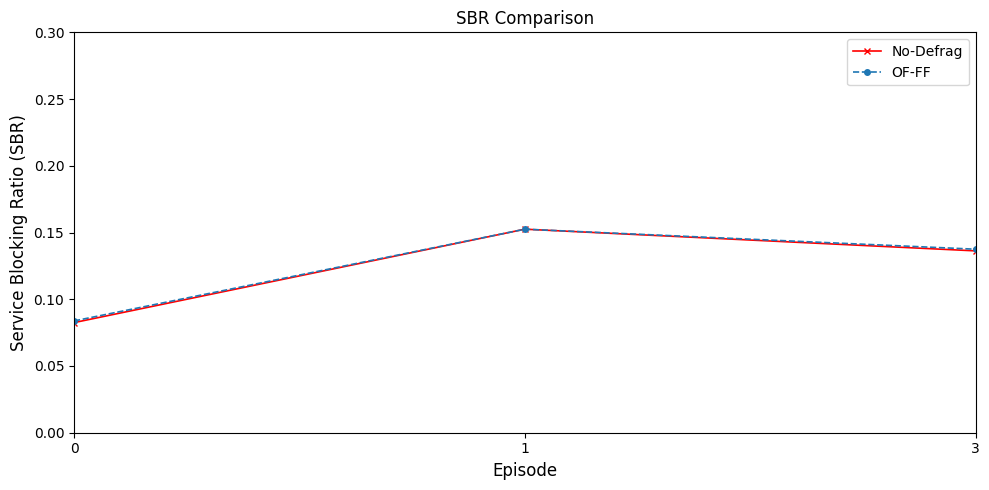

In [25]:


# 1) SBR curves
sbr_curves = {}

if "no_defrag_sbr" in results2:
    sbr_curves["No-Defrag"] = results2["no_defrag_sbr"]

if "of_ff_sbr" in results2:
    sbr_curves["OF-FF"] = results2["of_ff_sbr"]

if "of_ff2_sbr" in results2:
    sbr_curves["OF-FF2"] = results2["of_ff2_sbr"]

if "drl_sbr" in results2:
    sbr_curves["DRL"] = results2["drl_sbr"]

plot_multiple_curves(
    sbr_curves,
    ylabel="Service Blocking Ratio (SBR)",
    title="SBR Comparison",
    smooth_window=2,
    ylim=(0.0, 0.3),
)

/tmp/ipykernel_3891396/4149992484.py:58: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim(0, max_n - 1)


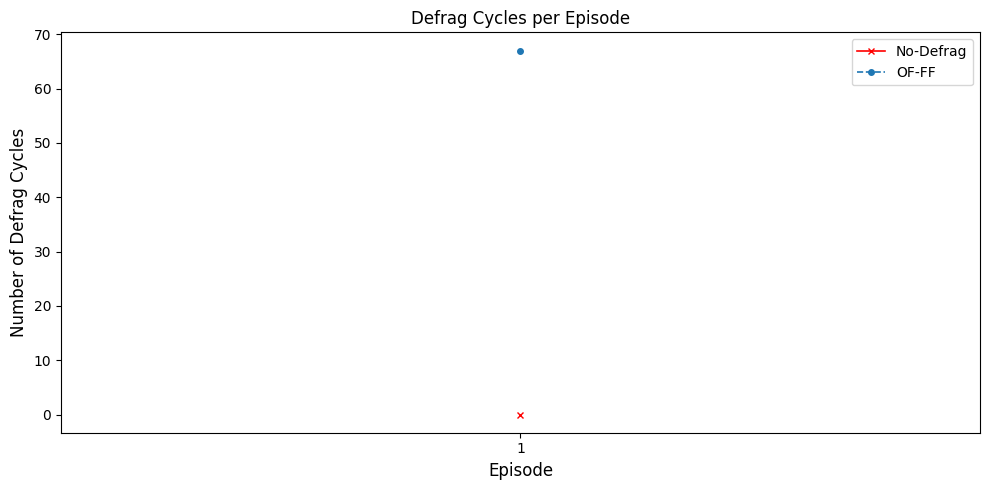

In [41]:
n_episodes = len(results2["no_defrag_sbr"])
defrag_curves = {}

if "no_defrag_sbr" in results2:
    defrag_curves["No-Defrag"] = np.zeros(n_episodes)

if "of_ff_defrag_cycles" in results2:
    defrag_curves["OF-FF"] = results2["of_ff_defrag_cycles"]

if "of_ff2_defrag_cycles" in results2:
    defrag_curves["OF-FF2"] = results2["of_ff2_defrag_cycles"]

if "drl_defrag_cycles" in results2:
    defrag_curves["DRL"] = results2["drl_defrag_cycles"]

plot_multiple_curves(
    defrag_curves,
    ylabel="Number of Defrag Cycles",
    title="Defrag Cycles per Episode",
    smooth_window=None,
)

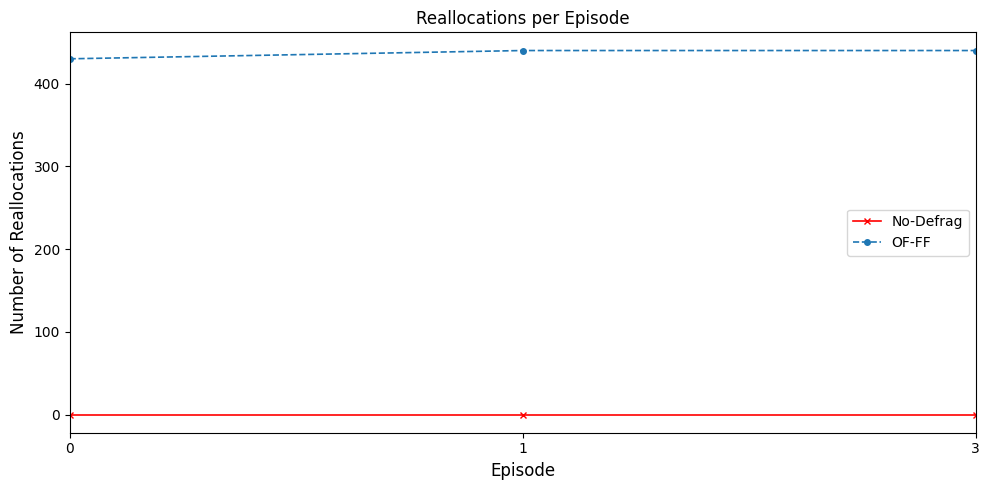

In [27]:
realloc_curves = {}
n_episodes = len(results2["no_defrag_sbr"])

if "no_defrag_sbr" in results2:
    realloc_curves["No-Defrag"] = np.zeros(n_episodes)

if "of_ff_reallocations" in results2:
    realloc_curves["OF-FF"] = results2["of_ff_reallocations"]

if "of_ff2_reallocations" in results2:
    realloc_curves["OF-FF2"] = results2["of_ff2_reallocations"]

if "drl_reallocations" in results2:
    realloc_curves["DRL"] = results2["drl_reallocations"]

plot_multiple_curves(
    realloc_curves,
    ylabel="Number of Reallocations",
    title="Reallocations per Episode",
    smooth_window=0,
)

In [28]:
print(results2["of_ff_reallocations"])

[430 440 440]


In [ ]:
curves = {}

label_map = {
    "no_defrag_sbr": "No-Defrag",
    "drl_sbr": "DRL",
}

for key, label in label_map.items():
    if key in results2:
        curves[label] = results2[key]

plot_multiple_sbr_curves(curves, smooth_window=2)